# RL Programming Crash Course

## PyTorch introduction

- An automatic differentiation (autodiff) library and much more!
- Bread and butter for machine learning
- [Installation](https://pytorch.org/get-started/locally/) `pip install torch`
- Consider Jax if you like functional programming. Big RL research ecosystem (Google DeepMind).

In [1]:
import torch
import matplotlib.pyplot as plt

Let's minimize $\text{loss}(\theta) = \theta^2$ using gradient descent. Initialize $\theta = 1$.

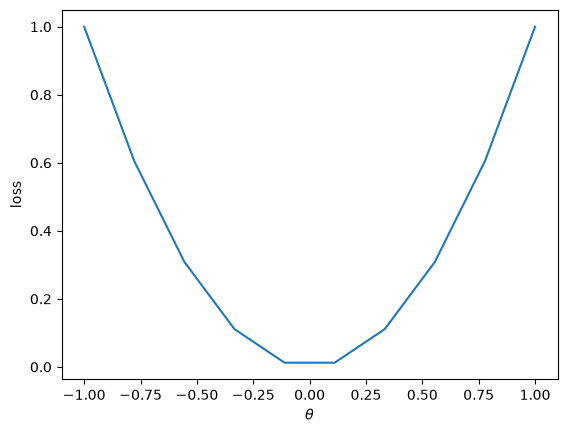

In [2]:
x = torch.linspace(-1, 1, 10)
y = x ** 2
plt.xlabel(r"$\theta$"); plt.ylabel(r"loss")
plt.plot(x, y); plt.show()

In [3]:
param = torch.tensor(1., requires_grad=True)
param

tensor(1., requires_grad=True)

In [4]:
loss = param ** 2
loss

tensor(1., grad_fn=<PowBackward0>)

In [5]:
loss.backward()  # computes d(loss)/d(theta) at theta
param.grad

tensor(2.)

In [6]:
optim = torch.optim.SGD((param,), lr=0.1)
optim.step()
param

tensor(0.8000, requires_grad=True)

## Tensor notation

Similar notation to NumPy:

| Type | Shape |
| - | - |
| Scalars | `()` |
| Vectors | `(n,)` |
| Matrices | `(n, m)` |
| Tensors | `(n0, n1, ...)` |

In [7]:
# Dungeons and Dragons character creation
# tensor with three axes: 5 characters, 6 ability scores, 4 six-sided dice
rolls = torch.randint(low=1, high=6+1, size=(5, 6, 4))
rolls

tensor([[[5, 1, 4, 1],
         [6, 5, 1, 4],
         [5, 1, 6, 1],
         [4, 1, 4, 6],
         [4, 6, 1, 4],
         [4, 1, 1, 5]],

        [[6, 5, 4, 6],
         [1, 3, 1, 6],
         [3, 3, 3, 1],
         [6, 1, 6, 2],
         [1, 2, 3, 5],
         [2, 1, 1, 5]],

        [[5, 5, 2, 5],
         [3, 6, 5, 2],
         [2, 1, 3, 6],
         [4, 1, 2, 1],
         [1, 2, 4, 4],
         [6, 6, 4, 6]],

        [[5, 2, 4, 6],
         [3, 2, 4, 2],
         [4, 4, 3, 4],
         [1, 3, 2, 2],
         [2, 5, 6, 5],
         [4, 6, 6, 1]],

        [[6, 3, 5, 1],
         [6, 3, 2, 4],
         [6, 1, 2, 2],
         [3, 6, 4, 4],
         [1, 2, 3, 5],
         [4, 1, 3, 2]]])

In [8]:
STR, DEX, CON, INT, WIS, CHA = 0, 1, 2, 3, 4, 5

In [9]:
rolls[:, DEX, :]  # everyone's dexterity rolls

tensor([[6, 5, 1, 4],
        [1, 3, 1, 6],
        [3, 6, 5, 2],
        [3, 2, 4, 2],
        [6, 3, 2, 4]])

In [10]:
# reduce along an axis
scores = rolls.sum(dim=2) - rolls.min(dim=2).values
scores

tensor([[10, 15, 12, 14, 14, 10],
        [17, 10,  9, 14, 10,  8],
        [15, 14, 11,  7, 10, 18],
        [15,  9, 12,  7, 16, 16],
        [14, 13, 10, 14, 10,  9]])

In [11]:
scores[:, CHA].sort(descending=True).indices

tensor([2, 3, 0, 4, 1])

In [12]:
# elementwise operations
modifiers = (scores - 10) // 2  # modifiers
modifiers

tensor([[ 0,  2,  1,  2,  2,  0],
        [ 3,  0, -1,  2,  0, -1],
        [ 2,  2,  0, -2,  0,  4],
        [ 2, -1,  1, -2,  3,  3],
        [ 2,  1,  0,  2,  0, -1]])

Now for **broadcasting**.
Each character gets a "proficiency bonus" based on level that applies to all abilities.

In [13]:
proficiency = torch.tensor([0, 2, 0, 1, 2])

# axes are right-aligned
# modifiers:   (5 players, 6 abilities)
# proficiency: (5 players,    new axis)
with_proficiency = modifiers + proficiency[:, torch.newaxis]
with_proficiency

tensor([[ 0,  2,  1,  2,  2,  0],
        [ 5,  2,  1,  4,  2,  1],
        [ 2,  2,  0, -2,  0,  4],
        [ 3,  0,  2, -1,  4,  4],
        [ 4,  3,  2,  4,  2,  1]])

Now for some advanced indexing.
Suppose players must succeed seven situations that require different abilities.

In [14]:
situations = torch.randint(low=0, high=6, size=(7,))
situations

tensor([1, 3, 4, 4, 3, 2, 4])

In [15]:
# index along an axis using a list or tensor
used_modifiers = with_proficiency[:, situations]
used_modifiers

tensor([[ 2,  2,  2,  2,  2,  1,  2],
        [ 2,  4,  2,  2,  4,  1,  2],
        [ 2, -2,  0,  0, -2,  0,  0],
        [ 0, -1,  4,  4, -1,  2,  4],
        [ 3,  4,  2,  2,  4,  2,  2]])

In [16]:
check_rolls = torch.randint(low=1, high=20+1, size=(5, 7))
successes = check_rolls + used_modifiers >= 15
successes

tensor([[False, False,  True, False, False, False,  True],
        [False, False, False, False,  True, False, False],
        [ True,  True, False, False,  True, False, False],
        [False, False, False, False, False, False, False],
        [ True,  True, False,  True,  True, False, False]])

In [17]:
successes.any(dim=0).all()

tensor(False)

## Supervised learning

$$
\argmin_{\theta \in \Theta}
\sum_{(x, y) \in \mathcal{D}}
\text{loss}(f_\theta(x), y)
$$

First define the function class to optimize over:

In [18]:
class Model(torch.nn.Module):
    def __init__(self, in_dim, out_dim, hidden_dim) -> None:
        super().__init__()
        self.ff0 = torch.nn.Linear(in_dim, hidden_dim)
        self.ff1 = torch.nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        x = self.ff0(x)
        x = torch.nn.functional.relu(x)
        x = self.ff1(x)
        return x

In [19]:
# create model
net = Model(1, 1, 32)
net

Model(
  (ff0): Linear(in_features=1, out_features=32, bias=True)
  (ff1): Linear(in_features=32, out_features=1, bias=True)
)

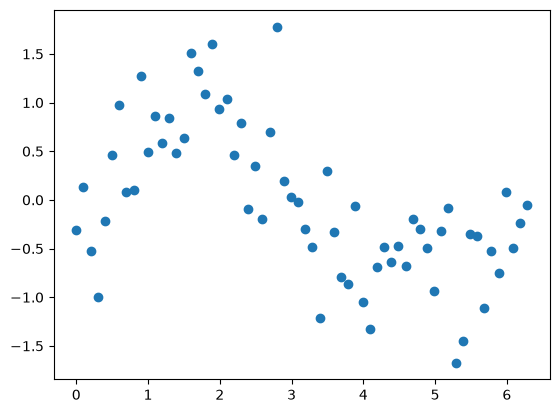

In [20]:
x = torch.linspace(0, 2*torch.pi, 64)[:, torch.newaxis]
y = torch.sin(x) + 0.5 * torch.randn_like(x)
plt.scatter(x, y)
plt.show()

In [21]:
# Dataset handles data loading (e.g. from files on disk)
dataset = torch.utils.data.TensorDataset(x, y)

# DataLoader handles batching and iteration
dataloader = torch.utils.data.DataLoader(dataset, batch_size=8, shuffle=True)

In [22]:
optim = torch.optim.AdamW(net.parameters(), lr=0.01)

for epoch in range(200):  # each epoch is one pass over the dataset
    for x_batch, y_batch in dataloader:
        optim.zero_grad()  # otherwise gradients accumulate
        pred_batch = net(x_batch)
        loss = torch.nn.functional.mse_loss(pred_batch, y_batch)
        loss.backward()  # sets `param.grad` for all parameters
        optim.step()  # updates parameters

loss

tensor(0.0694, grad_fn=<MseLossBackward0>)

In [53]:
len(optim.state)

6

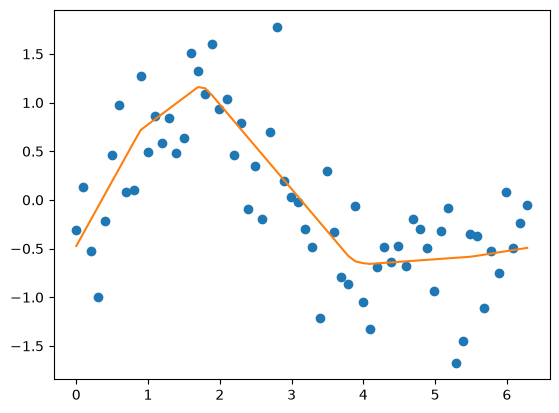

In [24]:
plt.scatter(x, y)
plt.plot(x, net(x).detach(), color='C1')
plt.show()

In [25]:
torch.save(net.state_dict(), 'model.pth')
! file model.pth

model.pth: Zip archive data, at least v0.0 to extract, compression method=store


In [26]:
net = Model(1, 1, 32)
net.load_state_dict(torch.load('model.pth'))

<All keys matched successfully>

## Gymnasium

- The standard RL programming interface
- Lots of alternatives
- v0.26 made breaking `terminated vs truncated` change (see [documentation](https://farama.org/Gymnasium-Terminated-Truncated-Step-API))

In [27]:
import gymnasium as gym

In [28]:
# making environments
env = gym.make('CartPole-v1', render_mode='rgb_array')
env.observation_space

Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)

In [29]:
env.action_space

Discrete(2)

In [30]:
# initial state
obs, info = env.reset()
obs.shape, obs.dtype, info

((4,), dtype('float32'), {})

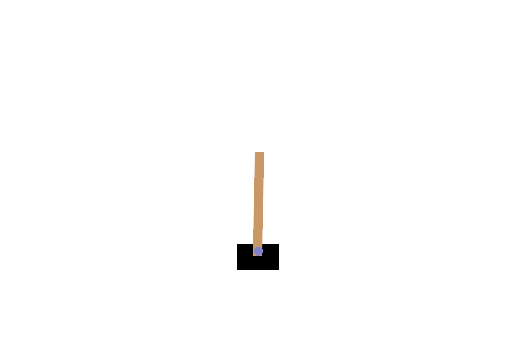

In [31]:
plt.imshow(env.render(), interpolation='none'); plt.axis('off'); plt.show()

In [32]:
# environment step
next_obs, reward, terminated, truncated, info = env.step(0)
reward, terminated, truncated, info

(1.0, False, False, {})

In [33]:
env.close()

### A simple algorithm

Wrappers are helpful!

In [34]:
from gymnasium.wrappers import NumpyToTorch

env = gym.make('CartPole-v1', max_episode_steps=200, render_mode='rgb_array')
env = NumpyToTorch(env)  # observations are already flat float32

In [35]:
network = torch.nn.Linear(env.observation_space.shape[-1], env.action_space.n)
network

Linear(in_features=4, out_features=2, bias=True)

In [36]:
network.weight

Parameter containing:
tensor([[ 0.2142, -0.3254, -0.1174, -0.3768],
        [-0.1907, -0.4176,  0.2458,  0.0062]], requires_grad=True)

In [37]:
obs, _ = env.reset()
network(obs)

tensor([-0.2893,  0.0976], grad_fn=<ViewBackward0>)

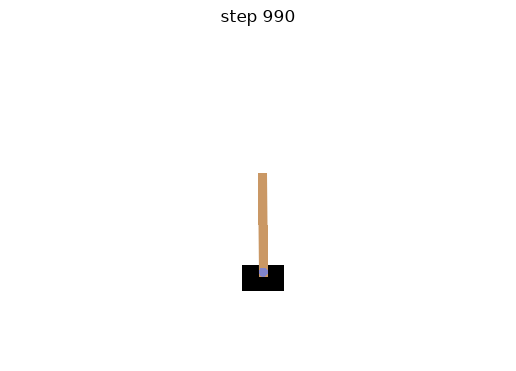

In [38]:
from IPython.display import clear_output

optim = torch.optim.AdamW(network.parameters(), lr=0.001)

episode_length = 0
episode_lengths = []

for step in range(1_000):
    with torch.no_grad():  # don't pass gradient through environment step
        # epsilon-greedy action in environment
        if torch.rand(()) < 0.9:
            action = network(obs).argmax()
        else:
            action = torch.randint(0, env.action_space.n, ())

        next_obs, reward, terminated, truncated, _ = env.step(action)
        target = reward + 0.99 * (not terminated) * network(next_obs).max()

    # gradients enabled
    optim.zero_grad()
    loss = 0.5 * (network(obs)[action] - target) ** 2
    loss.backward()
    optim.step()

    # visualization
    if step % 10 == 0:
        clear_output(wait=True); plt.imshow(env.render(), interpolation='none'); plt.title(f'step {step}'); plt.axis('off'); plt.show()

    if terminated or truncated:
        episode_lengths.append(episode_length)
        episode_length = 0
        obs, _ = env.reset()
    else:
        episode_length += 1
        obs = next_obs

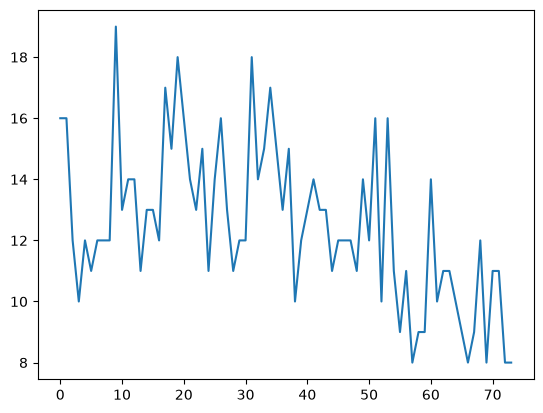

In [39]:
env.close()
plt.plot(episode_lengths)
plt.show()

## Vectorized Environments

Run many environments in parallel!

In [40]:
# import from vector submodule
from gymnasium.wrappers.vector import NumpyToTorch

class CleanStep(gym.vector.VectorWrapper):
    """float32 rewards; drop info (its `final_obs` object array can't be converted to torch)"""
    def step(self, actions):
        obs, reward, terminated, truncated, _ = self.env.step(actions)
        return obs, reward.astype('float32'), terminated, truncated, {}

# CartPole's built-in vector env only supports NEXT_STEP autoreset,
# so use 'sync' (8 copies of the single env), which accepts vector_kwargs
env = gym.make_vec('CartPole-v1', num_envs=8, max_episode_steps=200, vectorization_mode='sync',
                   vector_kwargs={'autoreset_mode': gym.vector.AutoresetMode.SAME_STEP})
env = CleanStep(env)  # observations are already flat float32
env = NumpyToTorch(env)
env.observation_space.shape

(8, 4)

In [41]:
env.action_space.shape

(8,)

In [42]:
obs_vec, _ = env.reset()
obs_vec

tensor([[-0.0375,  0.0470,  0.0317,  0.0479],
        [ 0.0073, -0.0212,  0.0253,  0.0413],
        [-0.0399,  0.0280,  0.0371, -0.0468],
        [ 0.0418,  0.0033, -0.0469,  0.0391],
        [-0.0293,  0.0427, -0.0127,  0.0339],
        [ 0.0474,  0.0060, -0.0382,  0.0017],
        [-0.0479,  0.0390, -0.0239,  0.0121],
        [-0.0184,  0.0330, -0.0142,  0.0312]])

In [ ]:
# hyperparameters from CleanRL's CartPole DQN (HW3)
network = torch.nn.Sequential(
    torch.nn.Linear(env.observation_space.shape[-1], 120), torch.nn.ReLU(),
    torch.nn.Linear(120, 84), torch.nn.ReLU(),
    torch.nn.Linear(84, env.single_action_space.n),
)
network(obs_vec)  # PyTorch automatically "vectorizes"

Let's note how the implementation changes:

In [44]:
action_vec = network(obs_vec).argmax(dim=-1)
action_vec  # useful trick is to initialize to uniform policy

tensor([0, 0, 0, 0, 0, 0, 0, 0])

In [45]:
next_obs_vec, reward_vec, terminated_vec, truncated_vec, _ = env.step(action_vec)
reward_vec

tensor([1., 1., 1., 1., 1., 1., 1., 1.])

In [46]:
target_vec = reward_vec + 0.99 * ~terminated_vec * network(next_obs_vec).max(dim=-1)[0]
target_vec

tensor([0.9523, 0.9505, 0.9529, 0.9486, 0.9512, 0.9490, 0.9511, 0.9508],
       grad_fn=<AddBackward0>)

In [47]:
q_vec = network(obs_vec)
q_vec

tensor([[-0.0315, -0.0488],
        [-0.0356, -0.0584],
        [-0.0283, -0.0523],
        [-0.0349, -0.0555],
        [-0.0322, -0.0500],
        [-0.0330, -0.0576],
        [-0.0315, -0.0494],
        [-0.0327, -0.0518]], grad_fn=<AddmmBackward0>)

In [48]:
prediction_vec = q_vec[torch.arange(8), action_vec]
prediction_vec

tensor([-0.0315, -0.0356, -0.0283, -0.0349, -0.0322, -0.0330, -0.0315, -0.0327],
       grad_fn=<IndexBackward0>)

In [49]:
optim = torch.optim.Adam(network.parameters(), lr=1e-3)

num_steps = 10_000
episode_length_vec = torch.zeros(8, dtype=torch.int)
episode_lengths = []

for step in range(num_steps):
    # epsilon decays linearly from 1 to 0.05 over the first half of training
    epsilon = max(0.05, 1 - 0.95 * step / (0.5 * num_steps))

    with torch.no_grad():
        explore_vec = torch.rand((8,)) < epsilon
        random_action_vec = torch.randint(0, 2, (8,))
        exploit_action_vec = network(obs_vec).argmax(dim=-1)
        action_vec = torch.where(explore_vec, random_action_vec, exploit_action_vec)
        next_obs_vec, reward_vec, terminated_vec, truncated_vec, _ = env.step(action_vec)

        target_vec = reward_vec + 0.99 * ~terminated_vec * network(next_obs_vec).max(dim=-1)[0]

    done_vec = terminated_vec | truncated_vec
    episode_length_vec += 1
    episode_lengths.extend(episode_length_vec[done_vec].tolist())
    episode_length_vec[done_vec] = 0

    pred_vec = network(obs_vec)[torch.arange(8), action_vec]

    optim.zero_grad()
    loss = torch.nn.functional.mse_loss(pred_vec, target_vec)
    loss.backward()
    optim.step()

    obs_vec = next_obs_vec

    if (step + 1) % 1_000 == 0 and episode_lengths:
        recent_lengths = episode_lengths[-100:]
        average_episode_length = sum(recent_lengths) / len(recent_lengths)
        print(f'Step {step + 1}: average episode length (last {len(recent_lengths)} episodes) = {average_episode_length:.1f}')

Step 1000: average episode length (last 100 episodes) = 25.3
Step 2000: average episode length (last 100 episodes) = 48.0
Step 3000: average episode length (last 100 episodes) = 83.4
Step 4000: average episode length (last 100 episodes) = 130.3
Step 5000: average episode length (last 100 episodes) = 174.4
Step 6000: average episode length (last 100 episodes) = 195.5
Step 7000: average episode length (last 100 episodes) = 191.1
Step 8000: average episode length (last 100 episodes) = 172.7
Step 9000: average episode length (last 100 episodes) = 173.4
Step 10000: average episode length (last 100 episodes) = 185.2


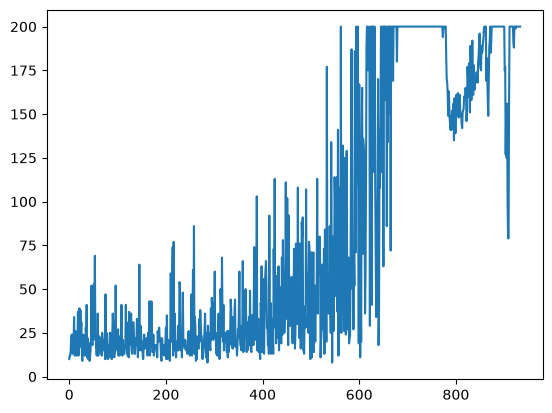

In [ ]:
plt.plot(episode_lengths)
plt.show()